# Objectif 

Recherche d'une situation passive favorable à la démonstration de la méthode de localisation dans le cas library passif / passif.

La zone est subdivisée en sous zone de taille réduite pour simplifier l'étude. Ce notebook illustre la procédure utiliser pour traiter chacune des sous zones. 

Date de création : 18/11/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from datetime import datetime

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_POSITIONS_NC_FPATH,
    ACOUPLANE_PRESSURE_NC_FPATH,
    ACOUPLANE_PASSIVE_NC_ROOT_FPATH,
)
from real_data_analysis.acouplane.src.acouplane_utils import (
    plot_spectrogram_section,
    plot_pressure_section,
)
from real_data_analysis.acouplane.src.analyse_passive_passive.acouplane_passive_passive_utils import (
    extract_ais_in_box,
    ais_to_distinct_events,
    assert_events_is_not_suspiciously_long,
    assert_no_events_during_emissions,
    assert_pressure_data_is_available,
    build_portion_events,
    plot_events_in_box,
    plot_events_temporal_coverage,
)

# Chargement des données 

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [3]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

## Signaux 

In [4]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 22GB
Dimensions:         (time_obs1: 996000000, time_obs2: 1000246750,
                     time_obs4: 993600000, time_obs5: 831600000,
                     time_obs6: 819000000, time_obs7: 850177000, obs_id: 6)
Coordinates:
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Dimensions without coordinates: time_obs1, time_obs2, time_obs4, time_obs5,
                                time_obs6, time_obs7
Data variables:
    pressure_obs1   (time_obs1) int32 4GB ...
    pressure_obs2   (time_obs2) int32 4GB ...
    pressure_obs4   (time_obs4) int32 4GB ...
    pressure_obs5   (time_obs5) int32 3GB ...
    pressure_obs6   (time_obs6) int32 3GB ...
    pressure_obs7   (time_obs7) int32 3GB ...
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

# Étude des positions des sources passives 

## Large box pour référence 

In [5]:
# Step 1: select AIS pos in the area of interest
lon_offset_percentage = lat_offset_percentage = 0.0025

rcv_id_for_area_def = [
    "obs1",
    "obs2",
    "obs4",
    "obs7",
    "obs5",
    # "obs6",
]       # Remove OBS 6 to reduce area 
ds_pos_area = ds_pos.sel(rcv_id=rcv_id_for_area_def)

# rcv_network_center_lon, rcv_network_center_lat = (
#     ds_pos_area.rcv_lon.mean().values,
#     ds_pos_area.rcv_lat.mean().values,
# )
lon_min, lon_max = ds_pos_area.rcv_lon.min().values * (
    1 - lon_offset_percentage / 2
), ds_pos_area.rcv_lon.max().values * (1 + lon_offset_percentage / 2)
lat_min, lat_max = ds_pos_area.rcv_lat.min().values * (
    1 - lat_offset_percentage / 2
), ds_pos_area.rcv_lat.max().values * (1 + lat_offset_percentage / 2)

large_box = dict(lon_min=lon_min, lon_max=lon_max, lat_min=lat_min, lat_max=lat_max)

In [6]:
ds_ais_large_box = extract_ais_in_box(ds_pos, box=large_box)
events_large_box = ais_to_distinct_events(ds_ais_box=ds_ais_large_box)
portion_event_large_box = build_portion_events(events_large_box, box=large_box)
portion_event_large_box

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 363)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 3kB 0 1 2 3 4 5 6 7 ... 356 357 358 359 360 361 362
│   Attributes:
│       box_lon_min:  5.9286
│       box_lon_max:  6.0005
│       box_lat_min:  42.9562
│       box_lat_max:  43.1083
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 160)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T09:19:20 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 6.0 5.999 5.999 ... 5.929 5.929 5.929
    │           lat             (datetime) float64 1kB 43.07 43.07 43.07 ... 43.09 43.09
    │           start_datetime  datetime64[ns] 8B 2026-02-24T09:19:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T09:45:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 242)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-24T07:12:50 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 2kB 5.929 5.929 5.929 ... 5.929 5.929
    │           lat             (datetime) float64 2kB 43.09 43.09 43.09 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-24T07:12:50
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T07:53:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 184)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-26T08:35:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 5.929 5.929 5.929 ... 5.999 6.0 6.0
    │           lat             (datetime) float64 1kB 43.09 43.09 43.09 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-26T08:35:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-26T09:06:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     2
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 149)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T14:18:10 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 6.0 6.0 5.999 ... 5.929 5.929 5.929
    │           lat             (datetime) float64 1kB 43.06 43.07 43.07 ... 43.09 43.09
    │           start_datetime  datetime64[ns] 8B 2026-02-24T14:18:10
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T14:42:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     3
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 451)
    │       Coordinates:
    │         * datetime        (datetime) 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: xlabel='Longitude [°]', ylabel='Latitude [°]'>)

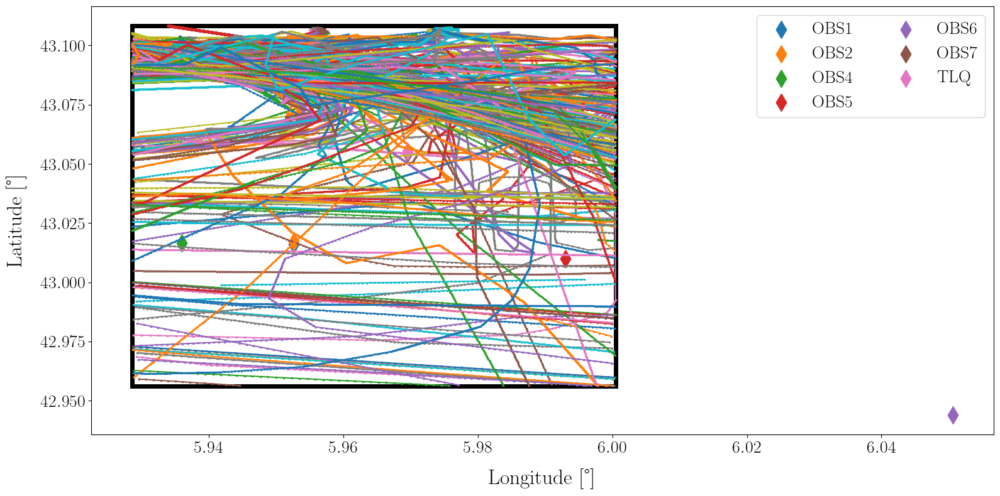

In [7]:
plot_events_in_box(ds_pos, portion_event_large_box)

## Définition d'une zone d'intérêt

On pave la zone large avec des sous box à étudier séparément pour simplifier l'étude. 

In [8]:
# Subdivise large box in subboxes
subbox_lon_width = subbox_lat_width = 0.02
large_box_lon_width = large_box["lon_max"] - large_box["lon_min"]
large_box_lat_width = large_box["lat_max"] - large_box["lat_min"]

n_box_lon = int(np.ceil(large_box_lon_width / subbox_lon_width))
n_box_lat = int(np.ceil(large_box_lat_width / subbox_lat_width))

sub_boxes = []
for i_subbox_lat in range(n_box_lat):
    lat_min = large_box["lat_min"] + i_subbox_lat * subbox_lat_width
    lat_max = min(lat_min + subbox_lat_width, large_box["lat_max"])

    for i_subbox_lon in range(n_box_lon):

        lon_min = large_box["lon_min"] + i_subbox_lon * subbox_lon_width
        lon_max = min(lon_min + subbox_lon_width, large_box["lon_max"])

        subbox_i = dict(lon_min=lon_min, lon_max=lon_max, lat_min=lat_min, lat_max=lat_max)
        
        sub_boxes.append(subbox_i)


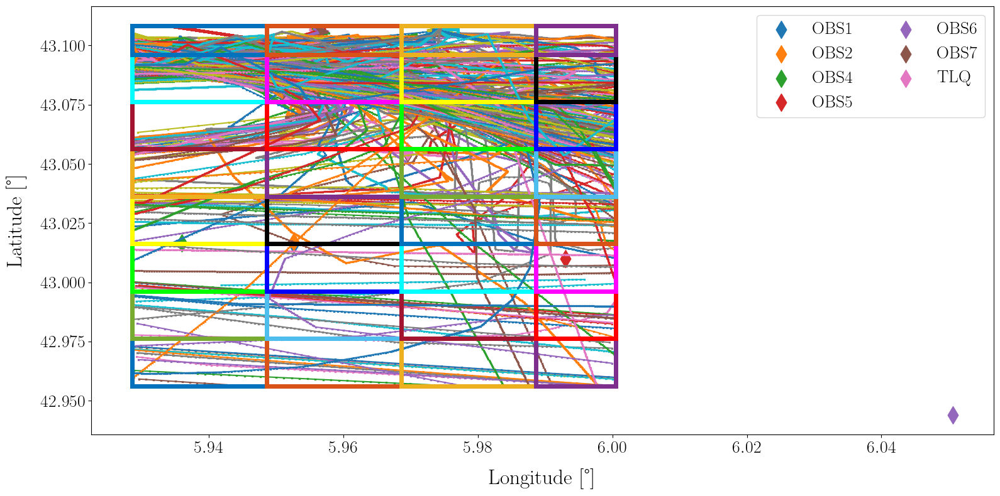

In [9]:
# Illustrate on map
fig, ax = plot_events_in_box(ds_pos, portion_event_large_box)

for ibox, box in enumerate(sub_boxes):
    # if ibox >= 1:
    #     continue

    lon_min = box.get("lon_min")
    lon_max = box.get("lon_max")
    lat_min = box.get("lat_min")
    lat_max = box.get("lat_max")

    # print(lon_min, lon_max, lat_min, lat_max)
    ax.add_patch(
        Rectangle(
            (lon_min, lat_min),
            lon_max - lon_min,
            lat_max - lat_min,
            fc="none",
            ec=color(ibox),
            lw=5,
            # label="Selected area",
            zorder=500,
        )
    )

# Illustration sur une unique box 

## Filtrage des trajectoires : disponibilité et viabilité des données acoustiques 

On filtre les trajectoires AIS en rejettant les trajectoires qui présentent un des deux critères suivant : 

* Les données acoustiques ne sont pas disponible (passage en dehors de la période d'acquisition)
* La trajectoires coincide avec une période d'activité de la source acoustique (canon)

In [10]:
box1 = sub_boxes[0]
ds_ais_box1 = extract_ais_in_box(ds_pos, box=box1)
events_box1 = ais_to_distinct_events(ds_ais_box=ds_ais_box1)
portion_event_box1 = build_portion_events(events_box1, box=box1)

### Premier tri : disponibilité des données OBS 

Dans un premier temps on sélectionne les évenement AIS pour lesquels on dispose des données OBS. 

In [11]:
# First filter
portion_event_box1 = assert_pressure_data_is_available(
    portion_event_box1, ds_pressure, verbose=False
)
portion_event_box1

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 10)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 80B 0 1 2 3 4 5 6 7 8 9
│   Attributes:
│       box_lon_min:  5.9286
│       box_lon_max:  5.9486
│       box_lat_min:  42.9562
│       box_lat_max:  42.9762
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 24)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 192B 2026-02-27T13:33:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 192B 5.948 5.947 5.947 ... 5.93 5.929
    │           lat             (datetime) float64 192B 42.96 42.96 42.96 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-27T13:33:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T13:37:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 15)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 120B 2026-02-28T14:25:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 120B 5.948 5.946 5.945 ... 5.931 5.929
    │           lat             (datetime) float64 120B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T14:25:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T14:27:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 39)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 312B 2026-02-24T03:23:00 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 312B 5.948 5.947 5.946 ... 5.947 5.948
    │           lat             (datetime) float64 312B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-24T03:23:00
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T19:23:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     2
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 37)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 296B 2026-02-26T03:14:10 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 296B 5.948 5.947 5.946 ... 5.947 5.948
    │           lat             (datetime) float64 296B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-26T03:14:10
    │           stop_datetime   datetime64[ns] 8B 2026-02-26T19:16:30
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     2
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 21)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 168B 2026-02-28T03:5

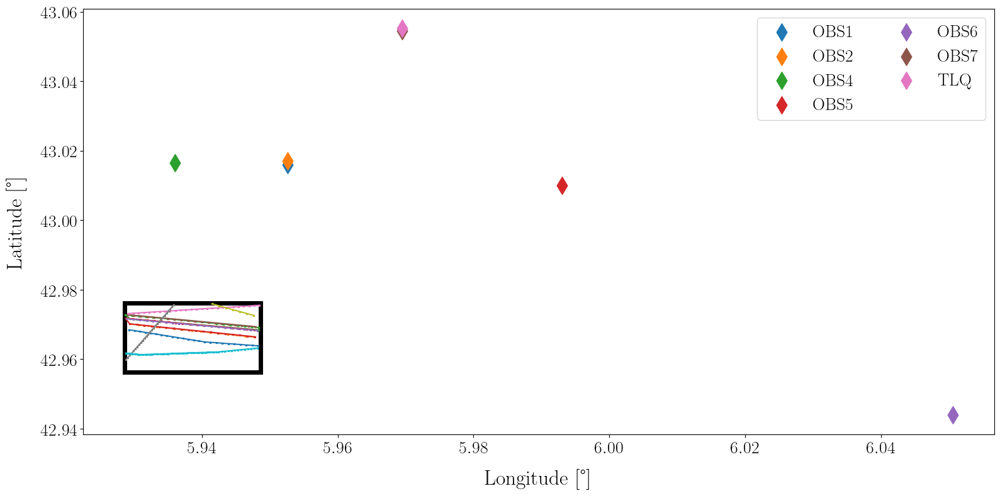

In [12]:
fig, ax = plot_events_in_box(ds_pos, portion_event_box1)

### Deuxième tri : donnée hors de la période des tirs 

On cherche ensuite des données hors de la période des émissions.

In [13]:
# Second filter
portion_event_box1 = assert_no_events_during_emissions(
    portion_event_box1, ds_pos, verbose=False
)
portion_event_box1

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 7)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 56B 0 1 2 3 4 5 6
│   Attributes:
│       box_lon_min:  5.9286
│       box_lon_max:  5.9486
│       box_lat_min:  42.9562
│       box_lat_max:  42.9762
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 24)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 192B 2026-02-27T13:33:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 192B 5.948 5.947 5.947 ... 5.93 5.929
    │           lat             (datetime) float64 192B 42.96 42.96 42.96 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-27T13:33:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T13:37:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 15)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 120B 2026-02-28T14:25:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 120B 5.948 5.946 5.945 ... 5.931 5.929
    │           lat             (datetime) float64 120B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T14:25:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T14:27:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 39)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 312B 2026-02-24T03:23:00 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 312B 5.948 5.947 5.946 ... 5.947 5.948
    │           lat             (datetime) float64 312B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-24T03:23:00
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T19:23:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     2
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 21)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 168B 2026-02-28T03:59:50 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 168B 5.948 5.947 5.946 ... 5.93 5.929
    │           lat             (datetime) float64 168B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T03:59:50
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T04:03:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 4
    │           MMSI:                     2
    ├── Group: /position/event_5
    │       Dimensions:         (datetime: 20)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 160B 2026-02-28T19:18:00 ...

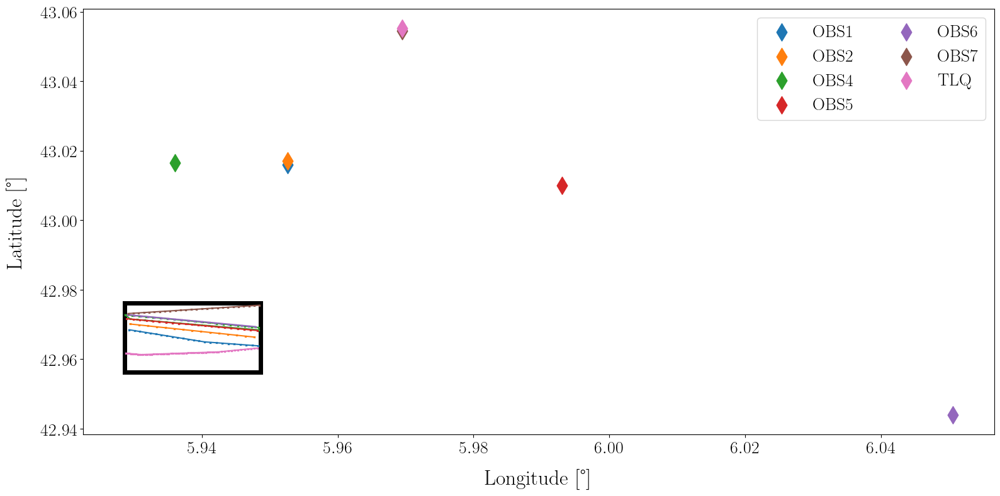

In [14]:
fig, ax = plot_events_in_box(ds_pos, portion_event_box1)

In [15]:
portion_event_box1 = assert_events_is_not_suspiciously_long(
    portion_event_box1, verbose=False, max_duration_min=30
)
portion_event_box1

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 6)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 48B 0 1 2 3 4 5
│   Attributes:
│       box_lon_min:  5.9286
│       box_lon_max:  5.9486
│       box_lat_min:  42.9562
│       box_lat_max:  42.9762
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 24)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 192B 2026-02-27T13:33:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 192B 5.948 5.947 5.947 ... 5.93 5.929
    │           lat             (datetime) float64 192B 42.96 42.96 42.96 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-27T13:33:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T13:37:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 15)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 120B 2026-02-28T14:25:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 120B 5.948 5.946 5.945 ... 5.931 5.929
    │           lat             (datetime) float64 120B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T14:25:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T14:27:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 21)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 168B 2026-02-28T03:59:50 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 168B 5.948 5.947 5.946 ... 5.93 5.929
    │           lat             (datetime) float64 168B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T03:59:50
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T04:03:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 4
    │           MMSI:                     2
    ├── Group: /position/event_5
    │       Dimensions:         (datetime: 20)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 160B 2026-02-28T19:18:00 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 160B 5.929 5.93 5.931 ... 5.947 5.948
    │           lat             (datetime) float64 160B 42.97 42.97 42.97 ... 42.97 42.97
    │           start_datetime  datetime64[ns] 8B 2026-02-28T19:18:00
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T19:21:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 5
    │           MMSI:                     2
    ├── Group: /position/event_7
    │       Dimensions:         (datetime: 26)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 208B 2026-03-01T03:02:00 ... 20

### Extraction signaux associés aux navires sélectionnés 

In [16]:
extract_pressure_events(portion_event_box1, ds_pressure)
portion_event_box1

NameError: name 'extract_pressure_events' is not defined

### Visualisation des signaux  

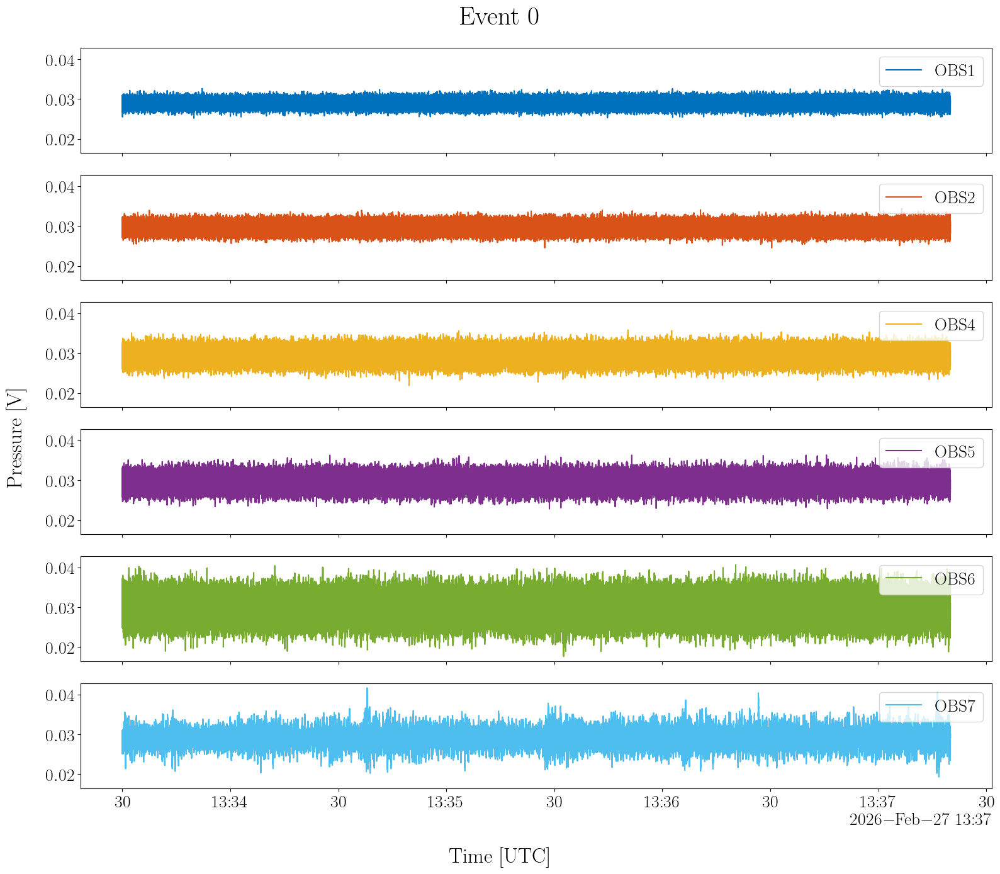

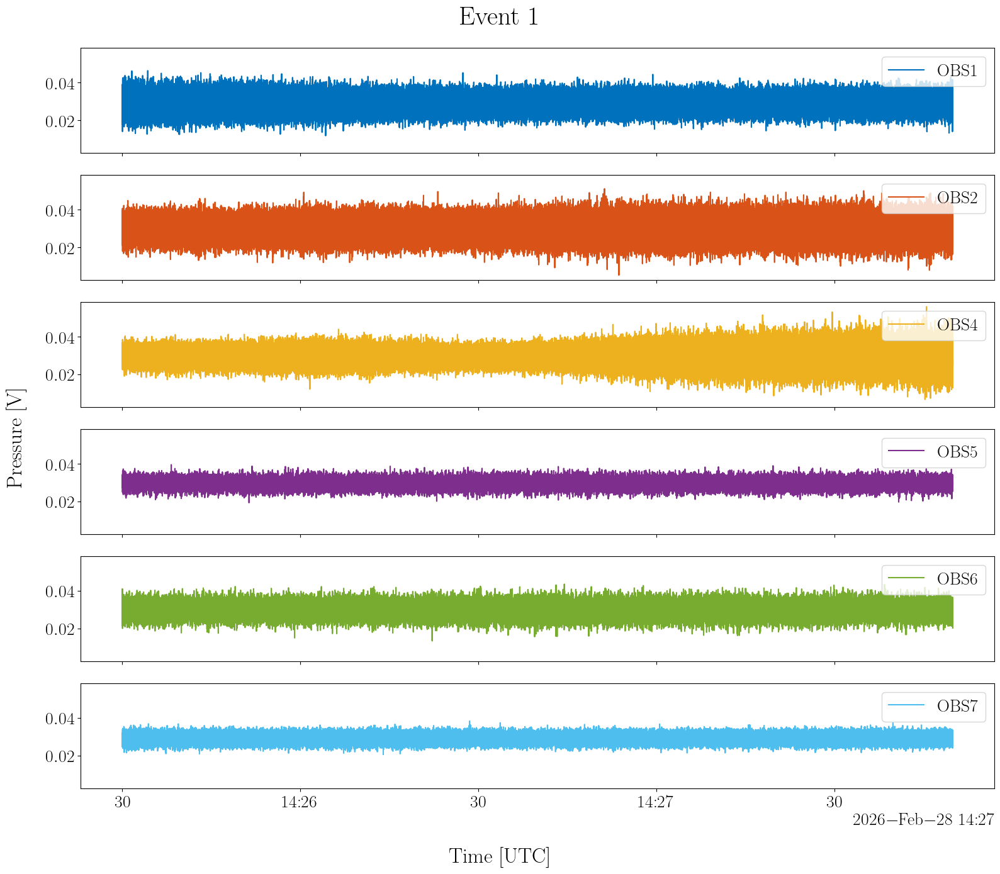

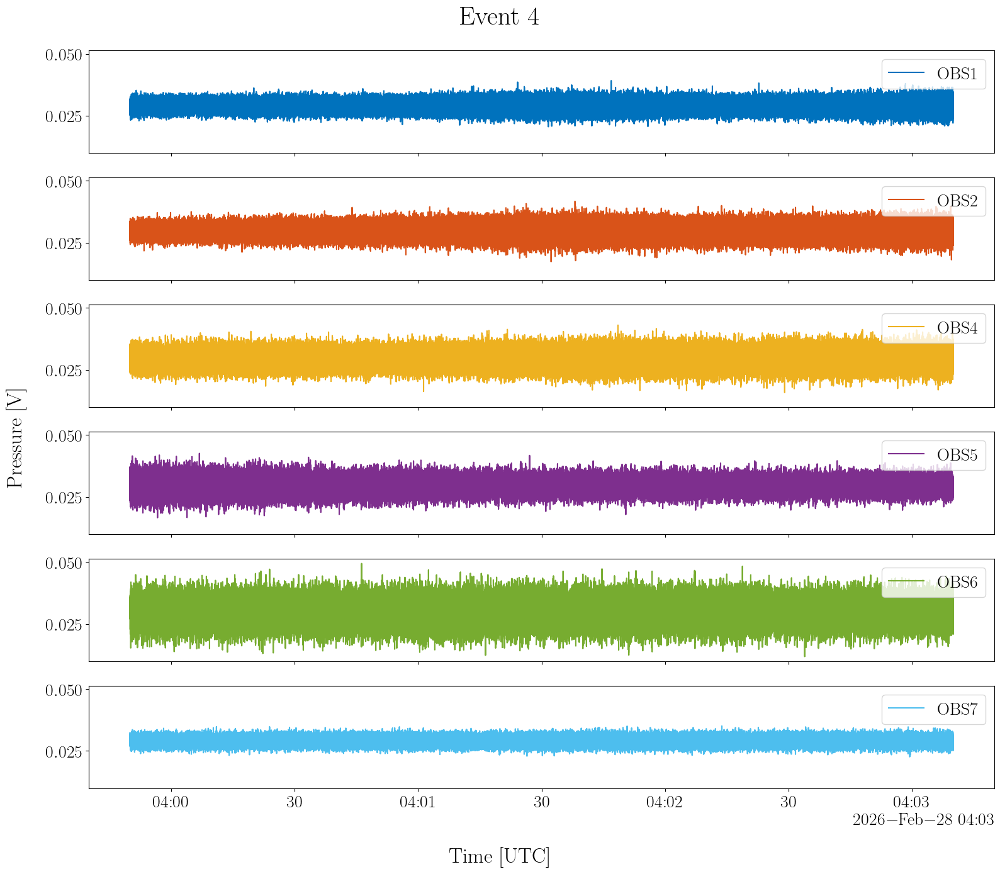

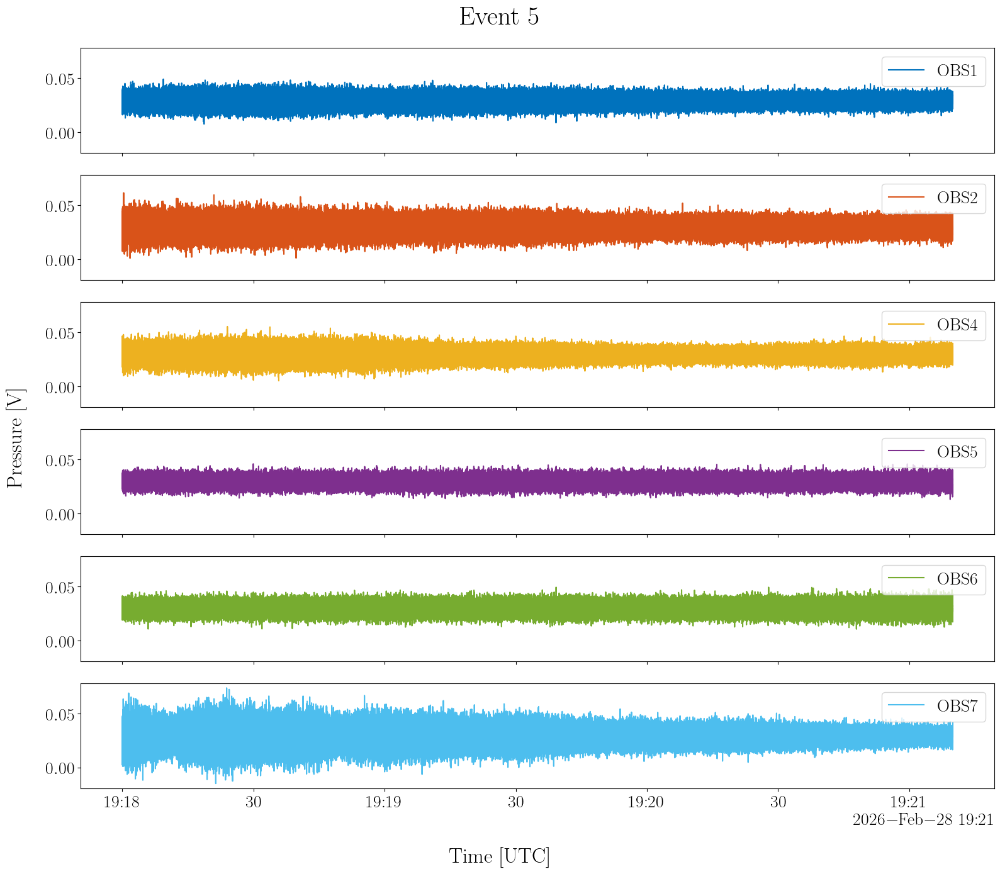

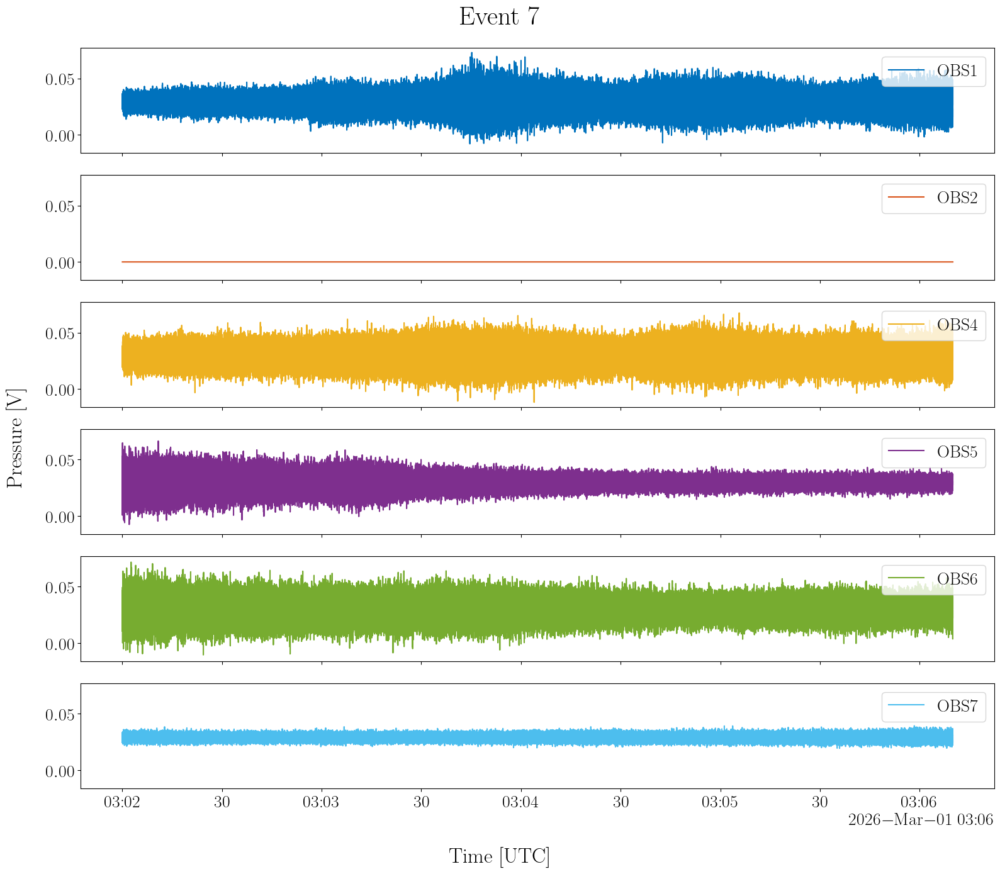

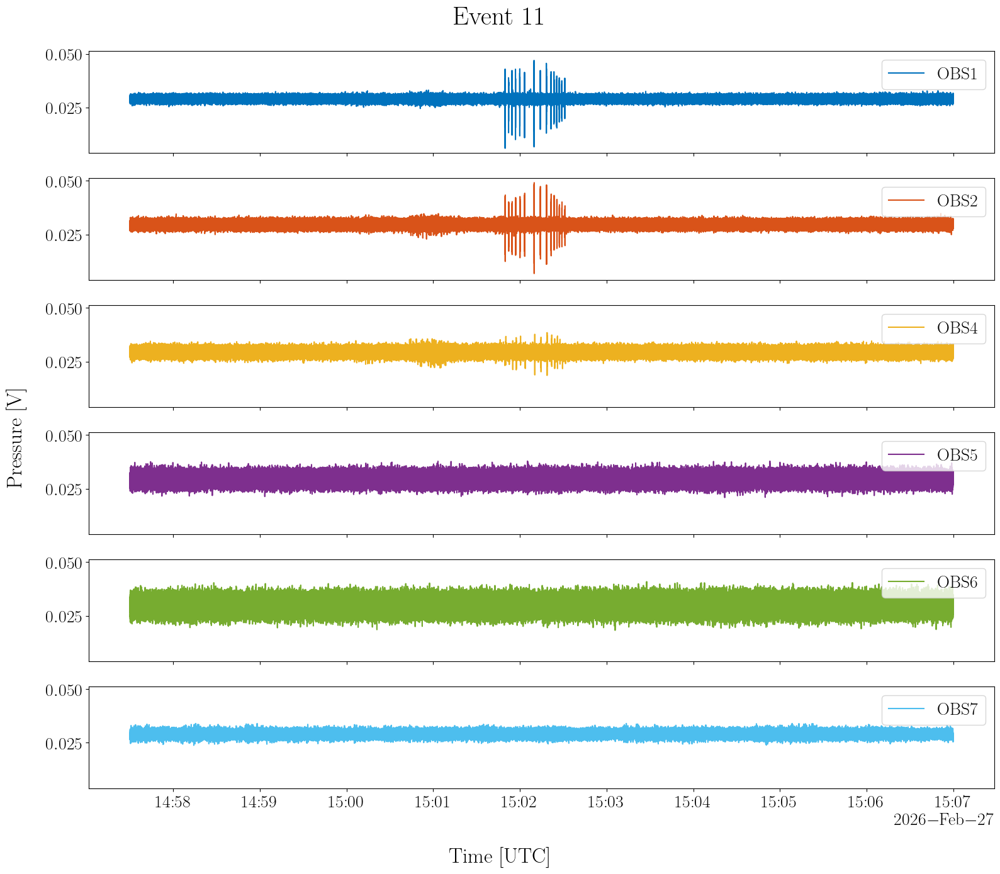

In [ ]:
# Plot
single_fig = False
for name, node in portion_event_box1.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    plt.show()

## Spectrogrames 


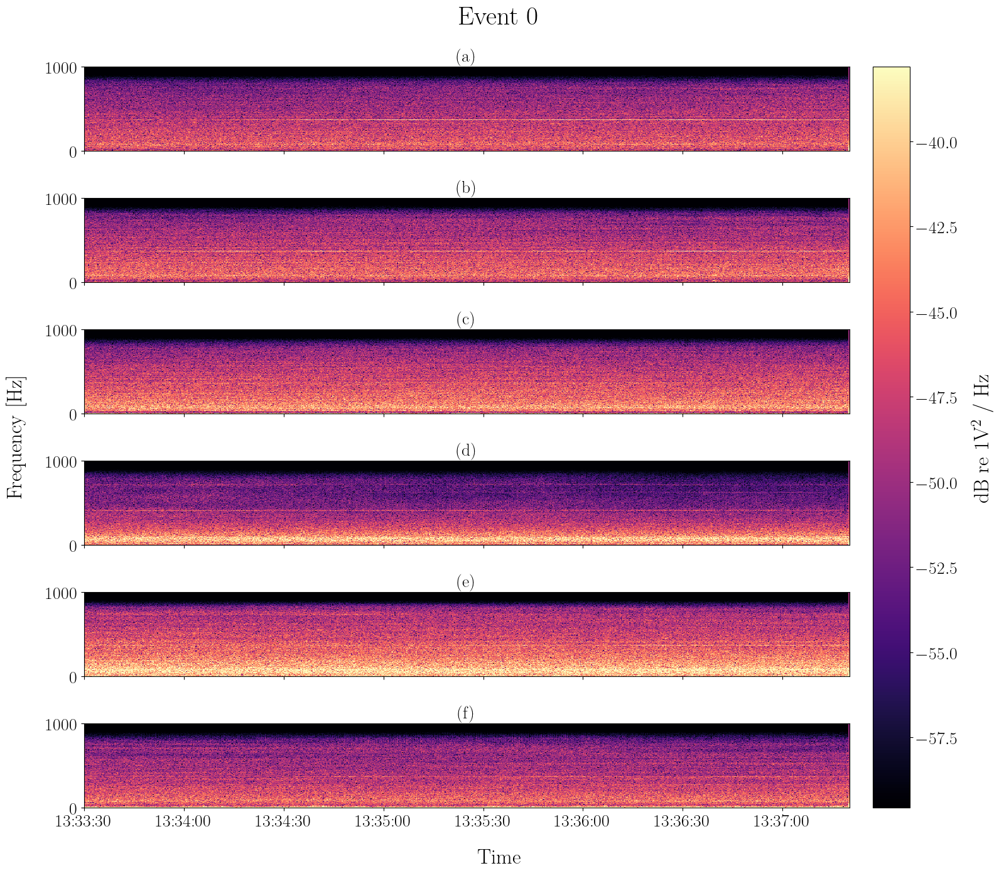

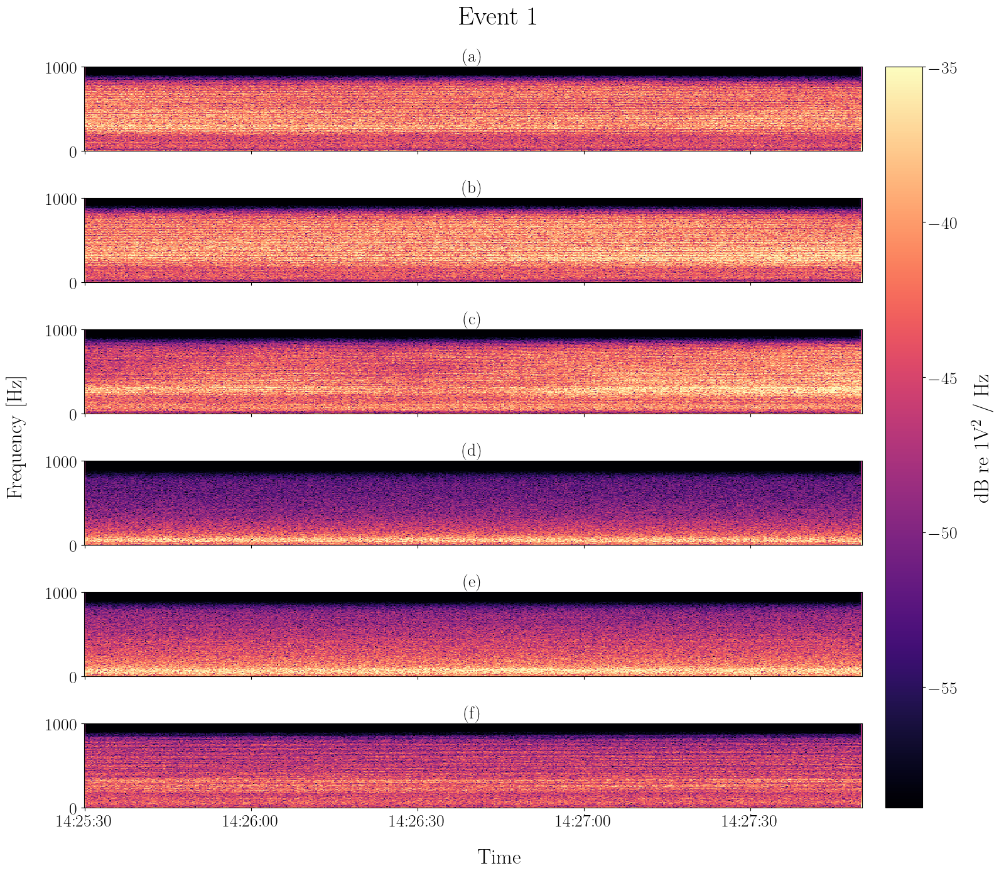

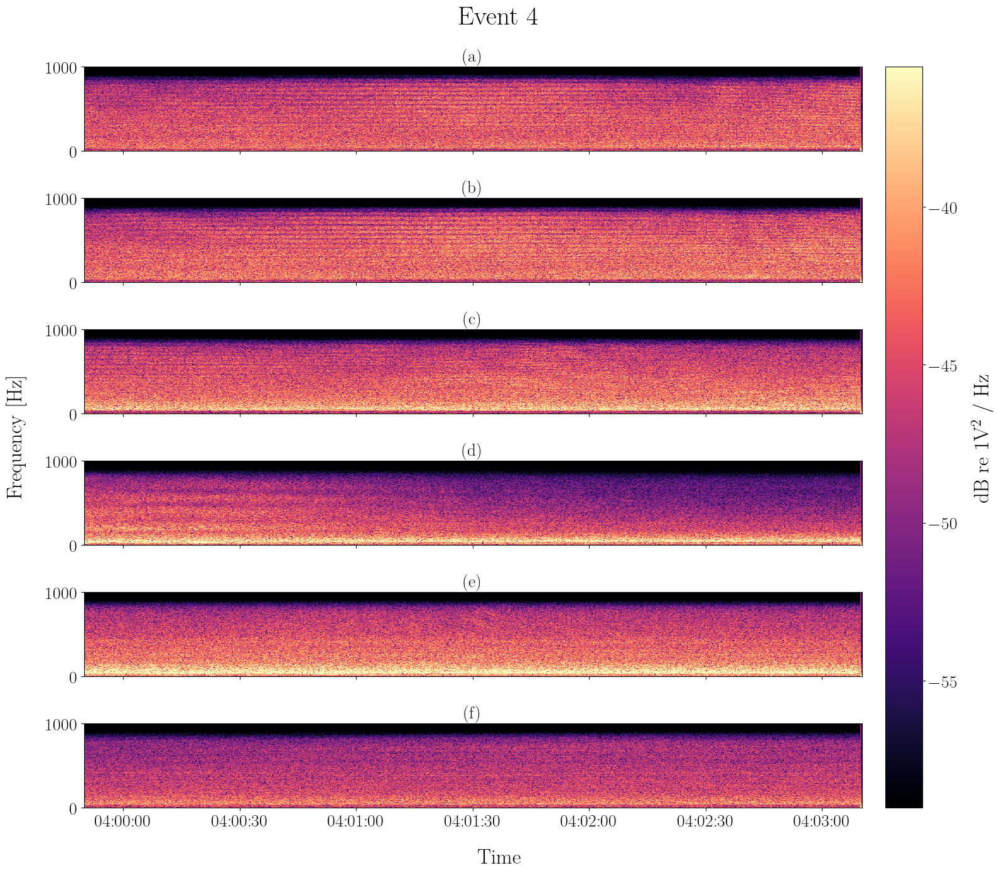

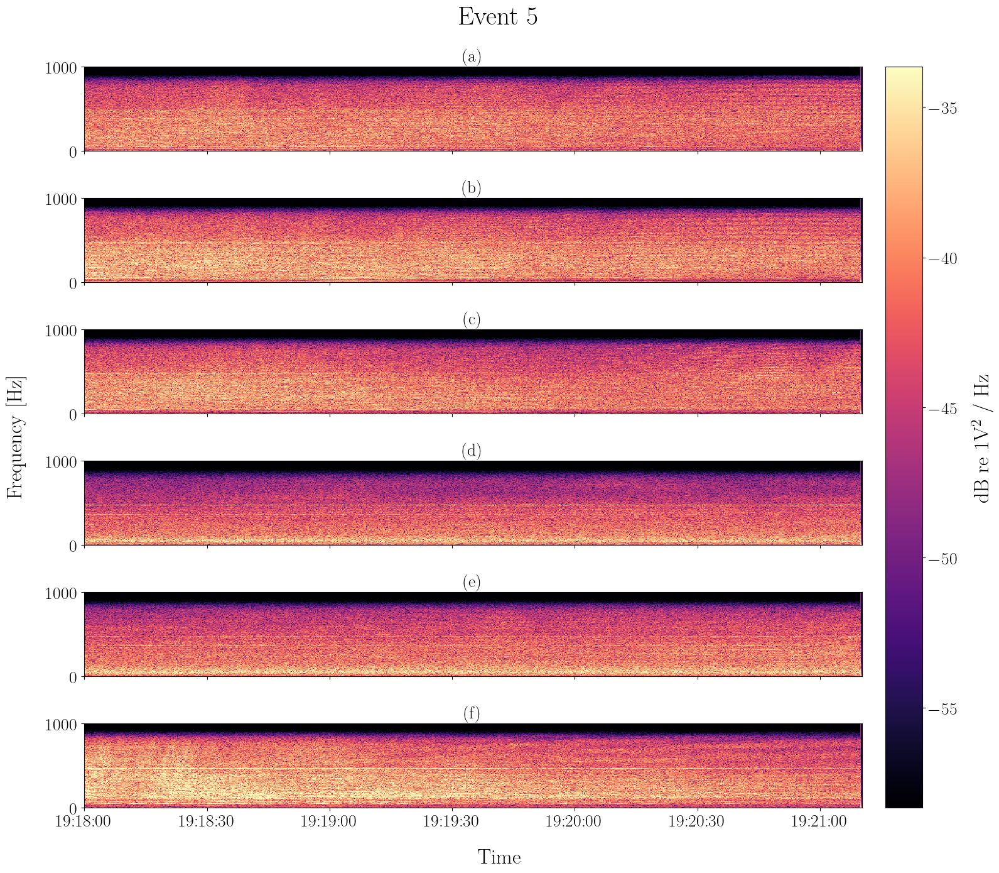

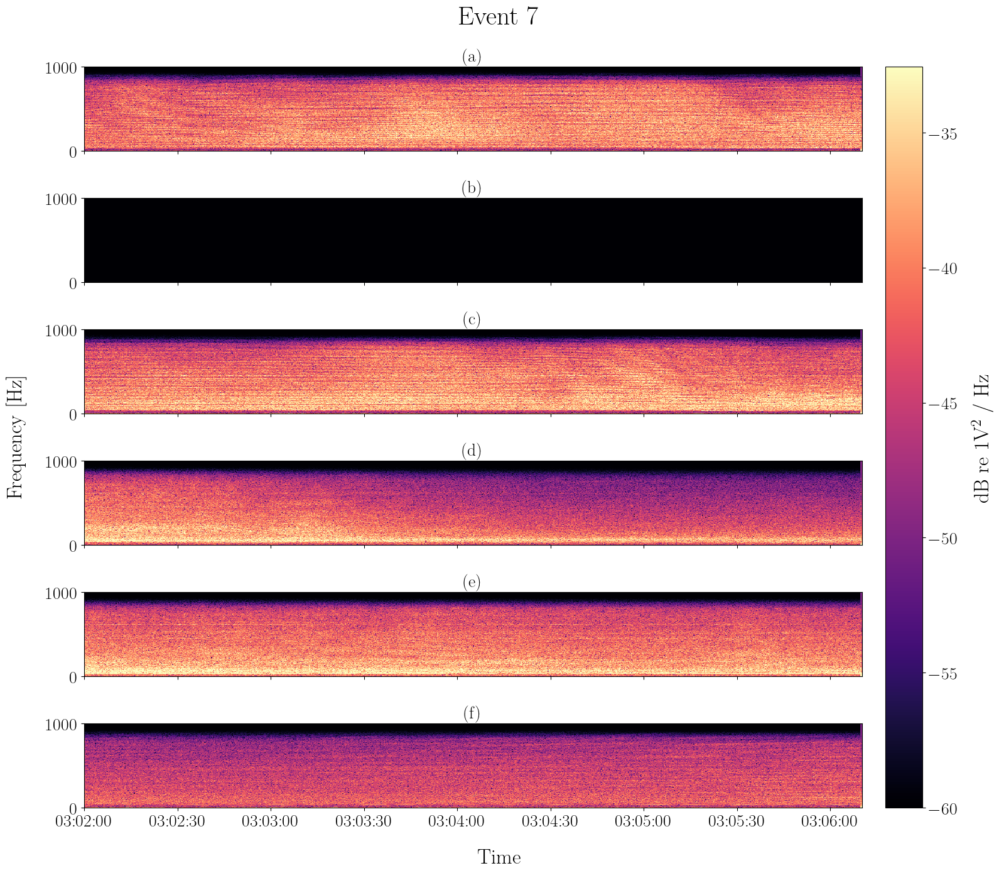

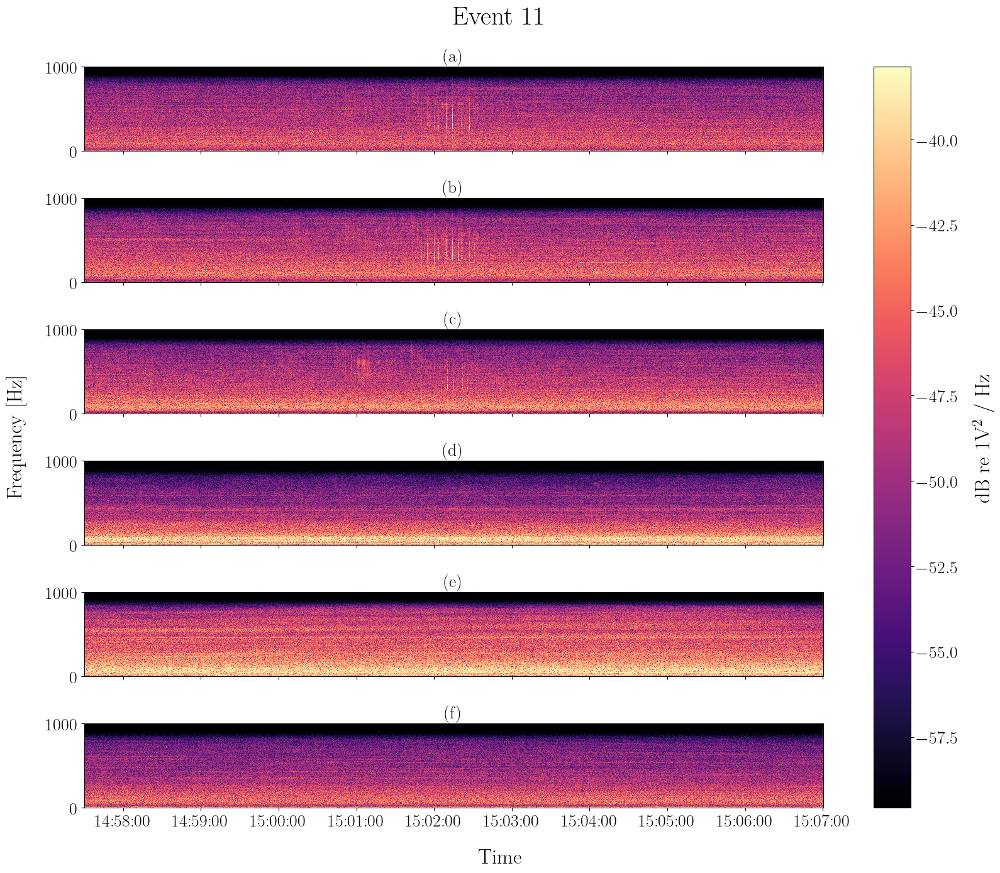

In [ ]:
# Plot
for name, node in portion_event_box1.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    try:
        fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
        fig.suptitle(f"Event {ds_pressure_section.event_id}")
    except:
        print(f"Data with different length event : {name}")
    plt.show()

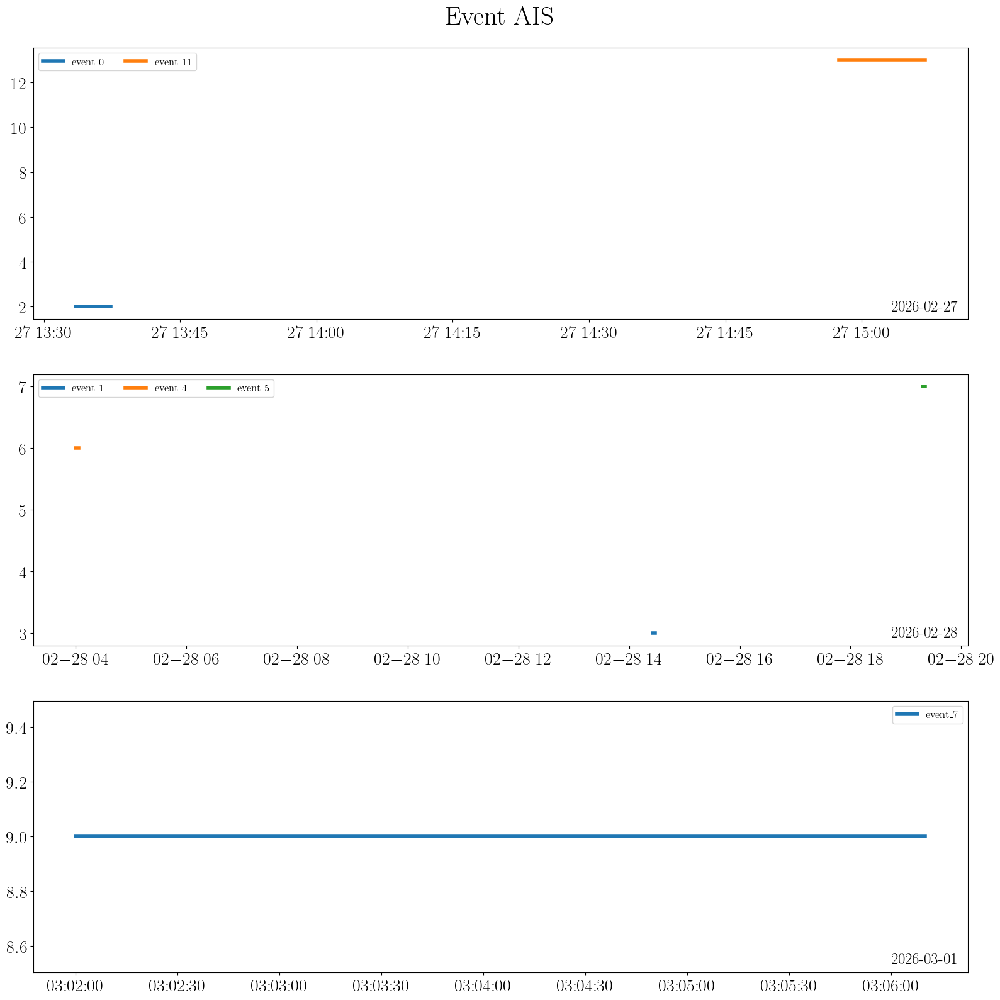

In [ ]:
plot_events_temporal_coverage(portion_event_box1)

# Sauvergarde de la portion event 

In [ ]:
# portion_event

NameError: name 'portion_event' is not defined

In [ ]:
# # Save as netcdf
# fpath = f"{ACOUPLANE_PASSIVE_NC_ROOT_FPATH}_ais_box.nc"
# portion_event.attrs["portion_filepath"] = fpath
# portion_event.to_netcdf(fpath)